In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
df=pd.read_csv('/content/Apartments Prices Dataset.csv')
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [5]:
df.shape

(5578, 11)

In [6]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [7]:
df.isnull().sum()

,0
price,0
area_sqm,0
rooms,0
bathrooms,0
floor_level,0
year_built,0
seller_type,0
view,0
price_per_sqm,0
payment_method,0


In [8]:
df.duplicated().sum()

np.int64(1489)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.shape

(4089, 11)

In [12]:
num = lambda s: pd.to_numeric(s.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
df["price"] = num(df["price"])
df["area_sqm"] = num(df["area_sqm"])
df["rooms"] = num(df["rooms"])
df["bathrooms"] = num(df["bathrooms"])
df["price_per_sqm"] = num(df["price_per_sqm"])
df["floor_level"] = df["floor_level"].replace("Ground", "0")
df["floor_level"] = pd.to_numeric(df["floor_level"], errors="coerce")

In [13]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,3,3,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000,162,3,2,6,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000,122,3,1,4,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000,212,4,3,13,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000,135,2,1,6,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux


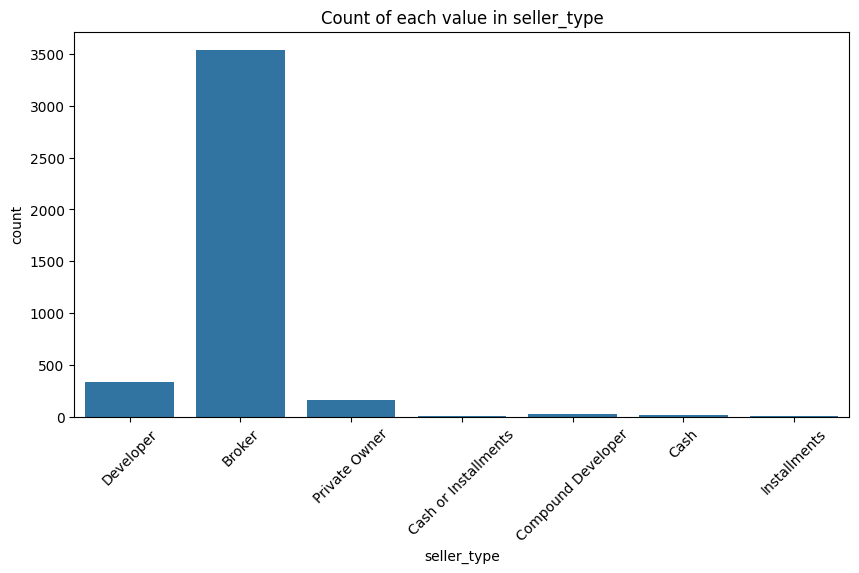

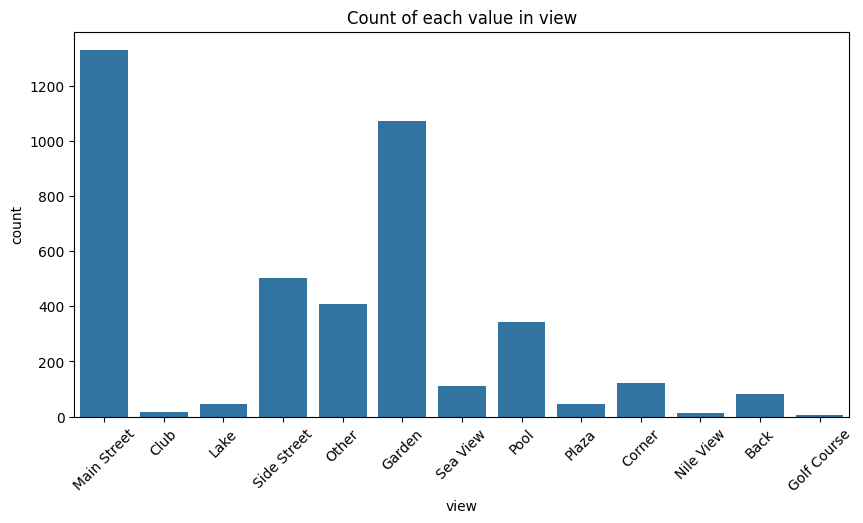

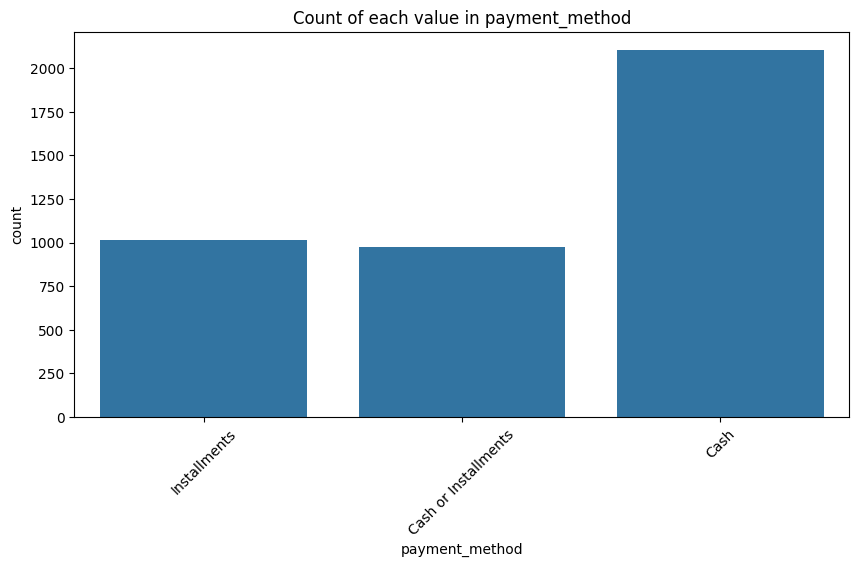

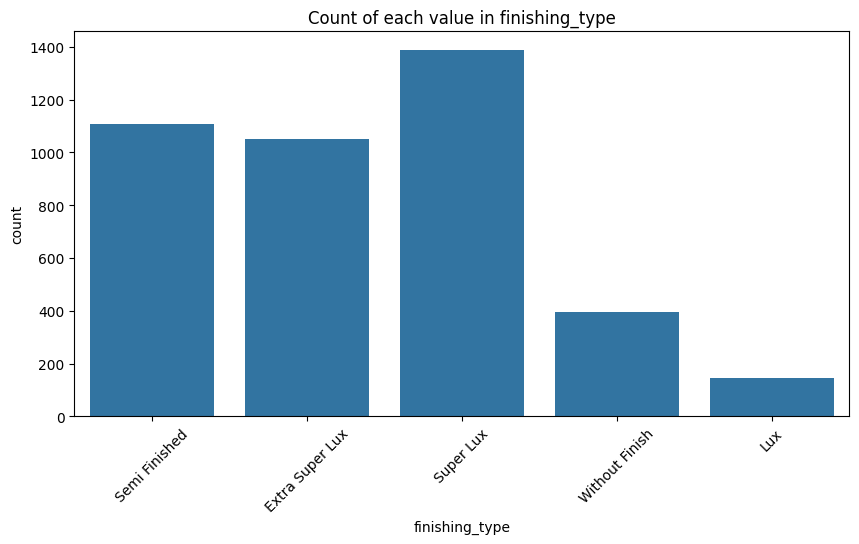

In [14]:
cat=df.select_dtypes(include='object')

for col in cat:
    plt.figure(figsize=(10, 5))

    sns.countplot(data=df, x=col)

    plt.title(f'Count of each value in {col}')
    plt.xticks(rotation=45)
    plt.show()

In [15]:
df.describe()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,price_per_sqm
count,4.089000e+03,4089.000000,4089.000000,4089.000000,4089.000000,4089.000000,4059.000000
mean,6.256734e+06,151.646857,2.716067,2.100758,2.986305,2021.928833,42771.296871
std,4.681578e+06,54.728073,4.125696,0.967992,2.789817,8.870374,28029.856346
min,5.000000e+05,15.000000,1.000000,1.000000,0.000000,1915.000000,4167.000000
25%,3.500000e+06,119.000000,2.000000,1.000000,1.000000,2022.000000,25000.000000
50%,5.160875e+06,150.000000,3.000000,2.000000,2.000000,2025.000000,36905.000000
75%,7.700000e+06,180.000000,3.000000,3.000000,4.000000,2026.000000,53914.000000
max,9.838000e+07,534.000000,230.000000,23.000000,64.000000,2037.000000,655172.000000


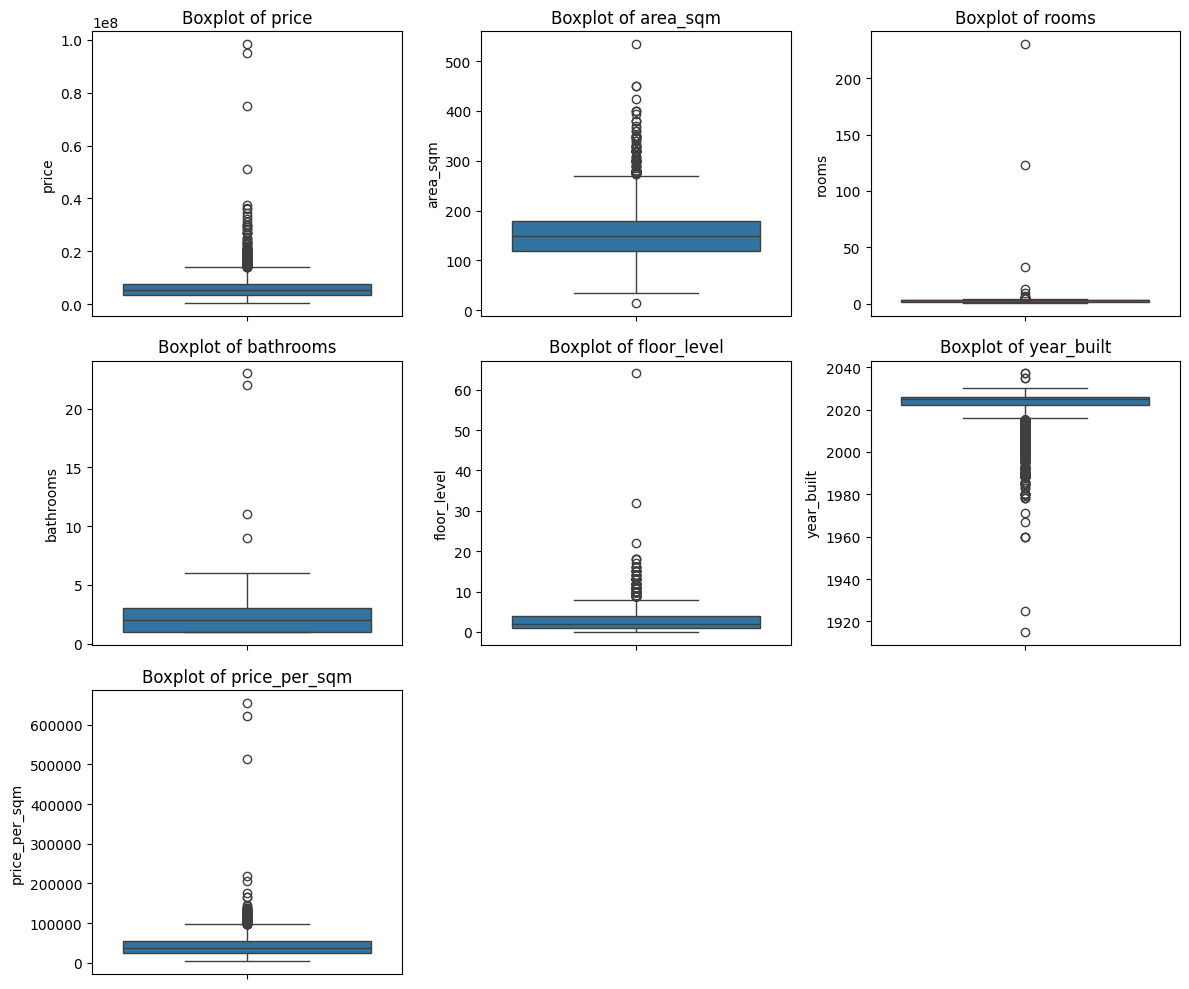

In [18]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(12, 10))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

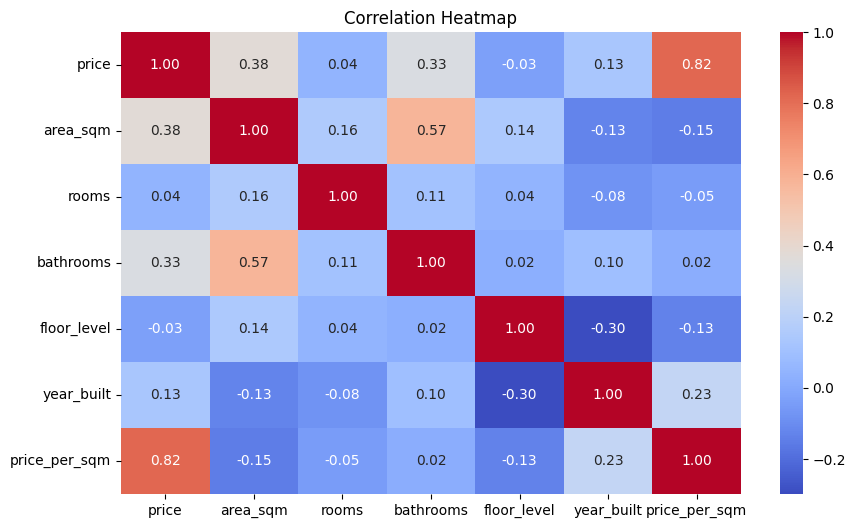

In [19]:


numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


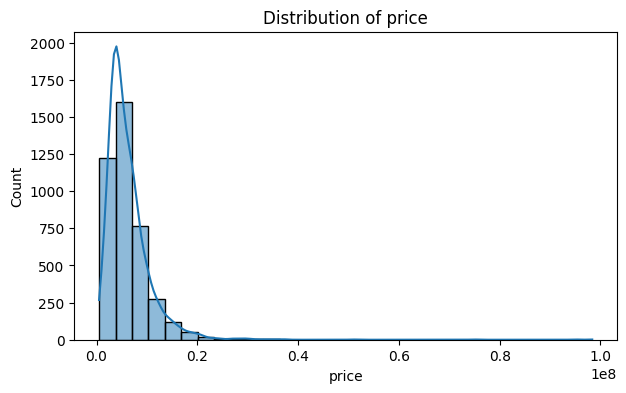

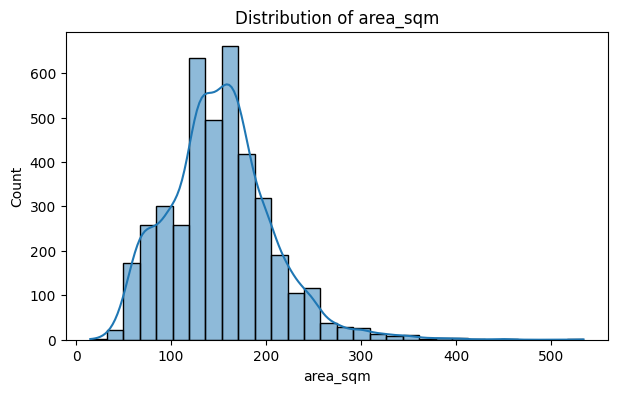

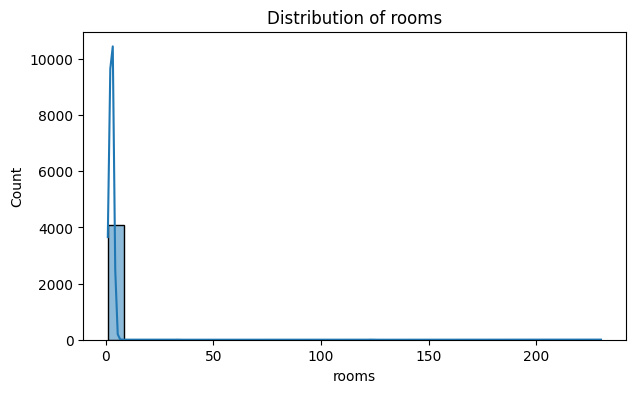

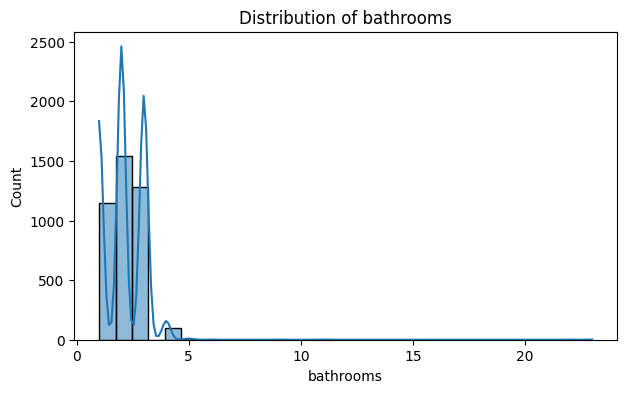

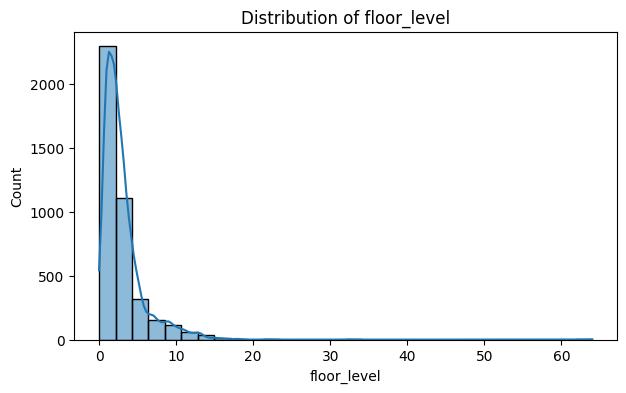

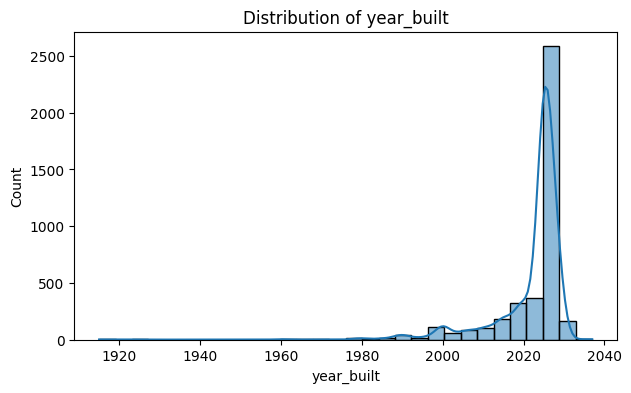

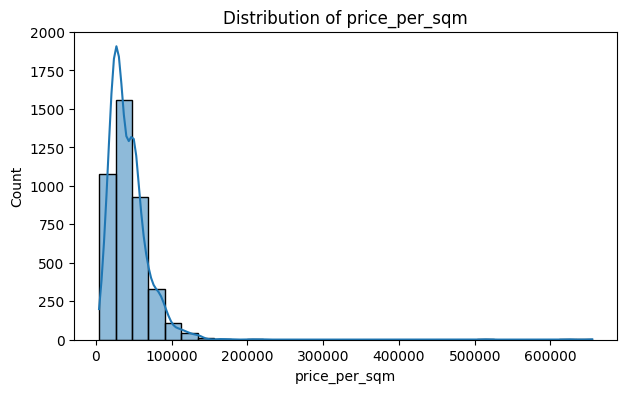

In [20]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


In [21]:
for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR

  outliers = df[
      (df[col] < lower) |
      (df[col] > upper)
  ]


  print("Number of Outliers:", len(outliers))

Number of Outliers: 196
Number of Outliers: 102
Number of Outliers: 26
Number of Outliers: 4
Number of Outliers: 227
Number of Outliers: 613
Number of Outliers: 123


In [22]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000,120,2,3,3,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000,162,3,2,6,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000,122,3,1,4,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000,212,4,3,13,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000,135,2,1,6,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux


In [24]:
x=df.drop('price',axis=1)
y=df['price']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [25]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
cat=x_train.select_dtypes(include='object')
for col in cat:
  x_train[col]=le.fit_transform(x_train[col])
  x_test[col]=le.transform(x_test[col])



In [26]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [27]:
pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 19.4 MB/s  0:00:05


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [29]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [30]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

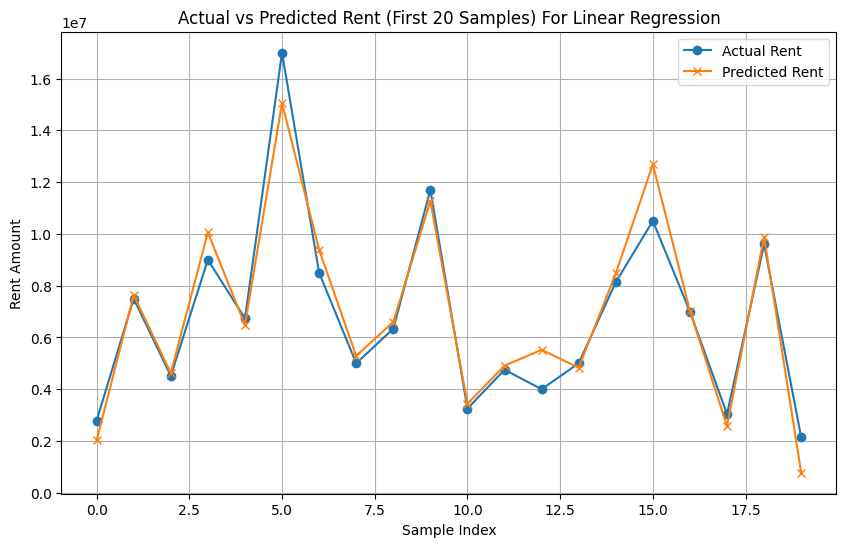

  7%|▋         | 1/15 [00:00<00:06,  2.31it/s]

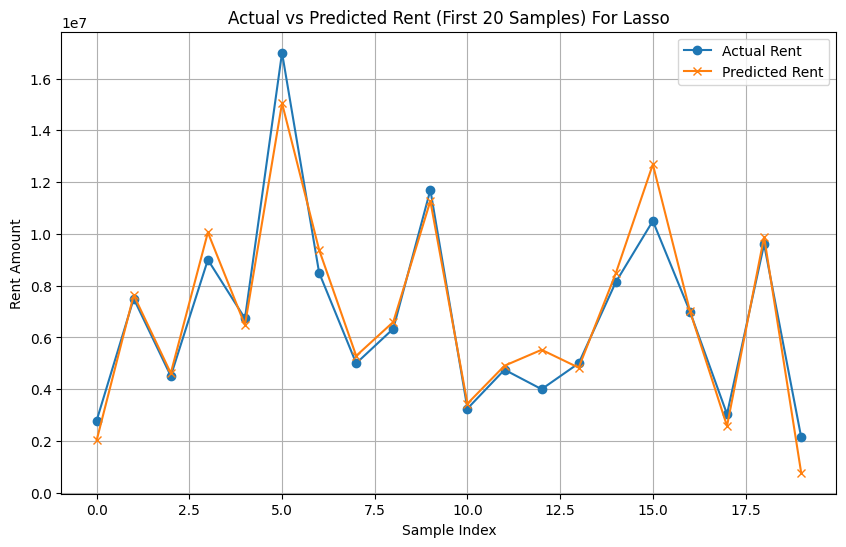

 13%|█▎        | 2/15 [00:00<00:05,  2.57it/s]

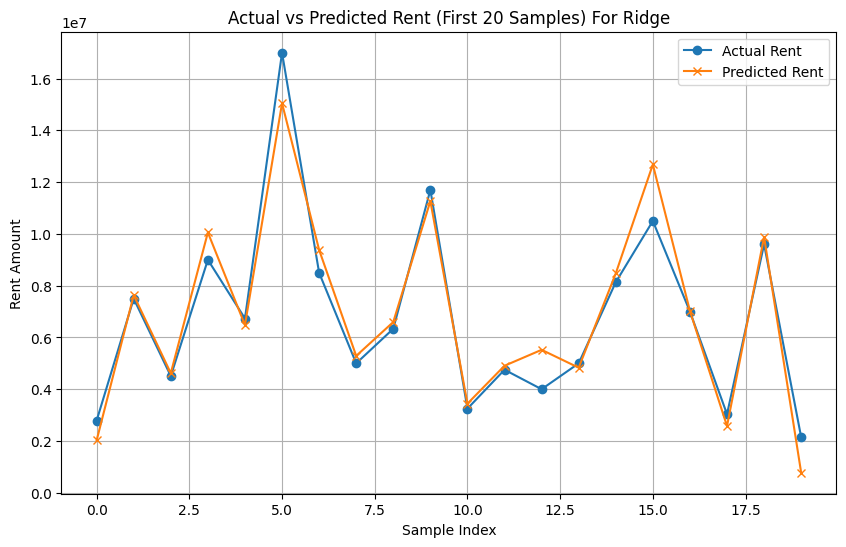

 20%|██        | 3/15 [00:01<00:04,  2.65it/s]

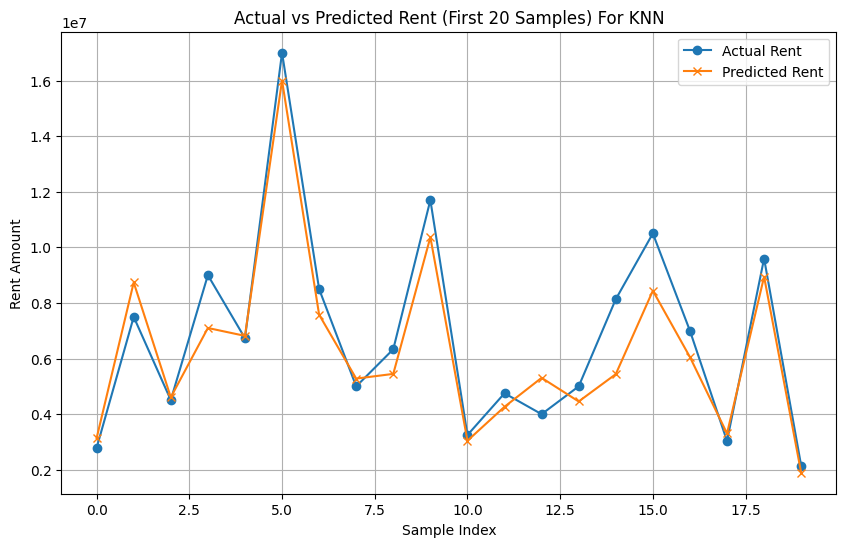

 27%|██▋       | 4/15 [00:02<00:08,  1.37it/s]

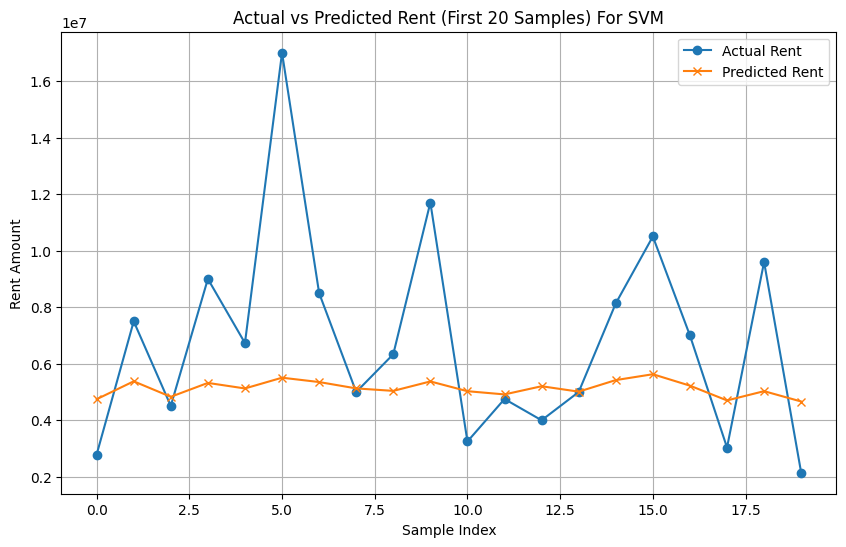

 33%|███▎      | 5/15 [00:04<00:10,  1.05s/it]

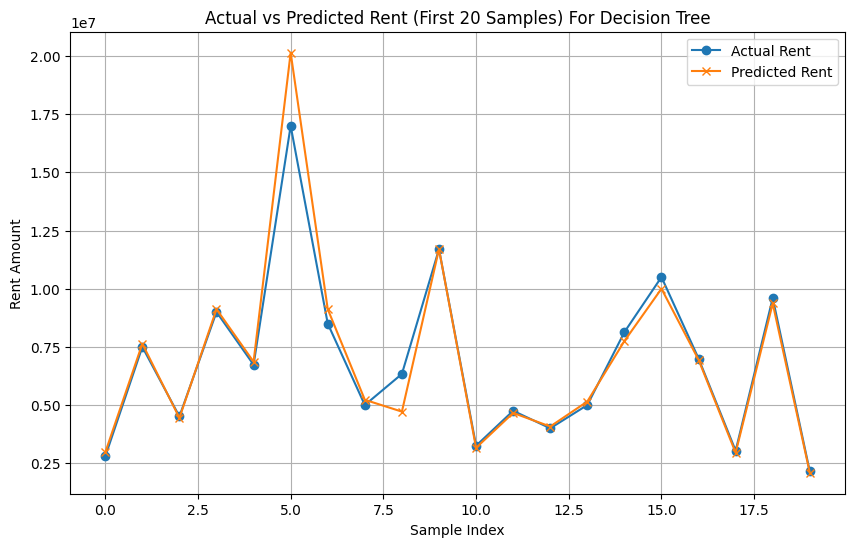

 40%|████      | 6/15 [00:04<00:07,  1.22it/s]

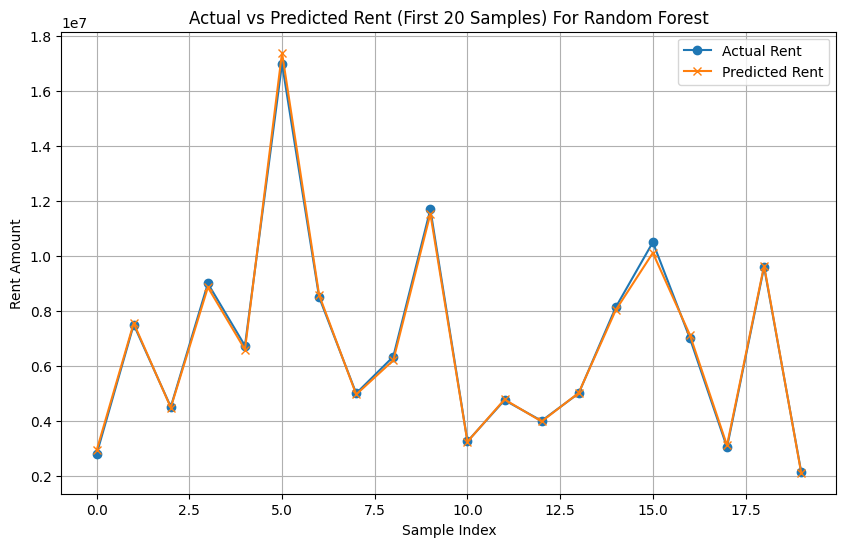

 47%|████▋     | 7/15 [00:05<00:07,  1.13it/s]

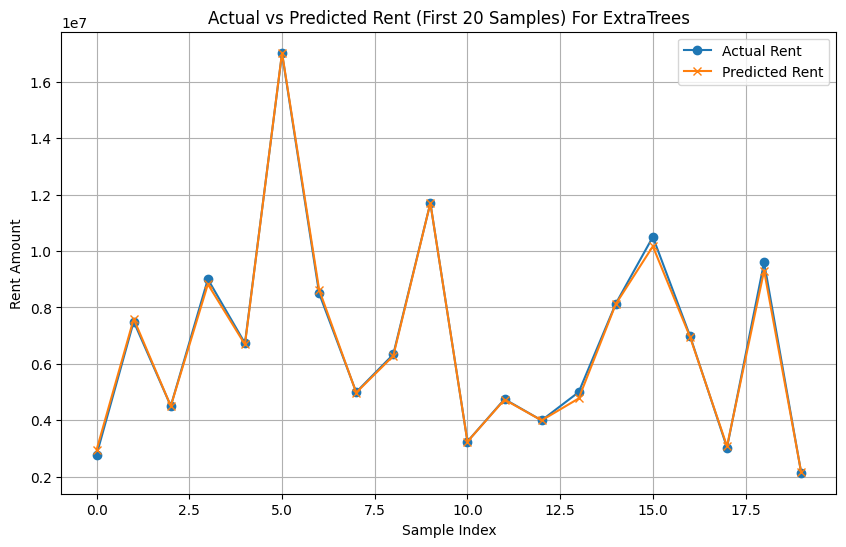

 53%|█████▎    | 8/15 [00:06<00:07,  1.03s/it]

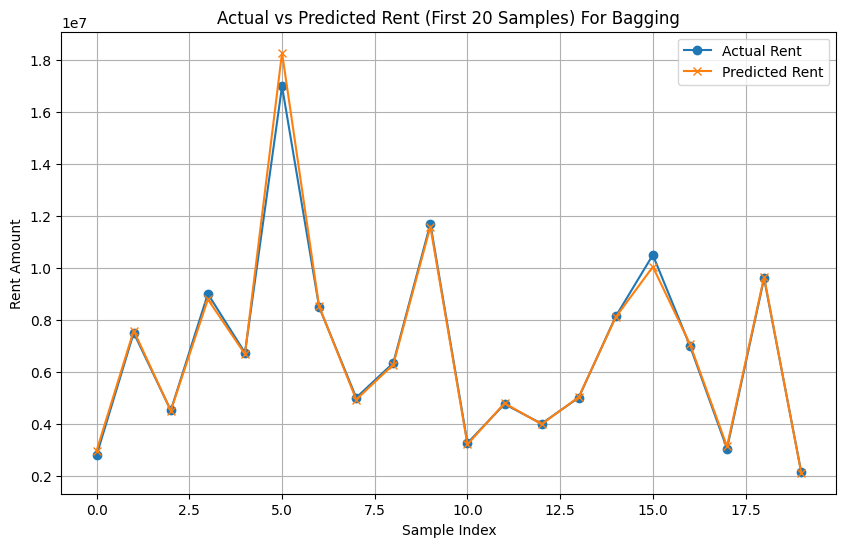

 60%|██████    | 9/15 [00:07<00:05,  1.03it/s]

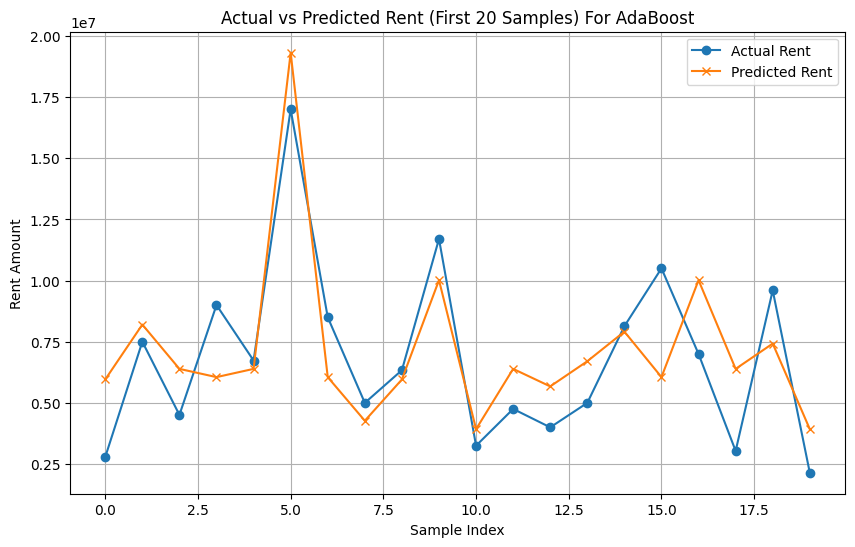

 67%|██████▋   | 10/15 [00:07<00:03,  1.31it/s]

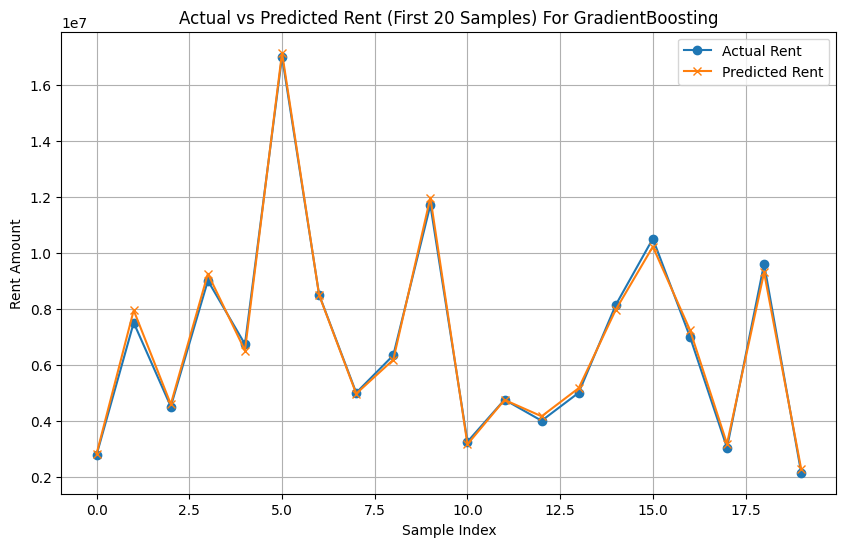

 73%|███████▎  | 11/15 [00:08<00:02,  1.37it/s]

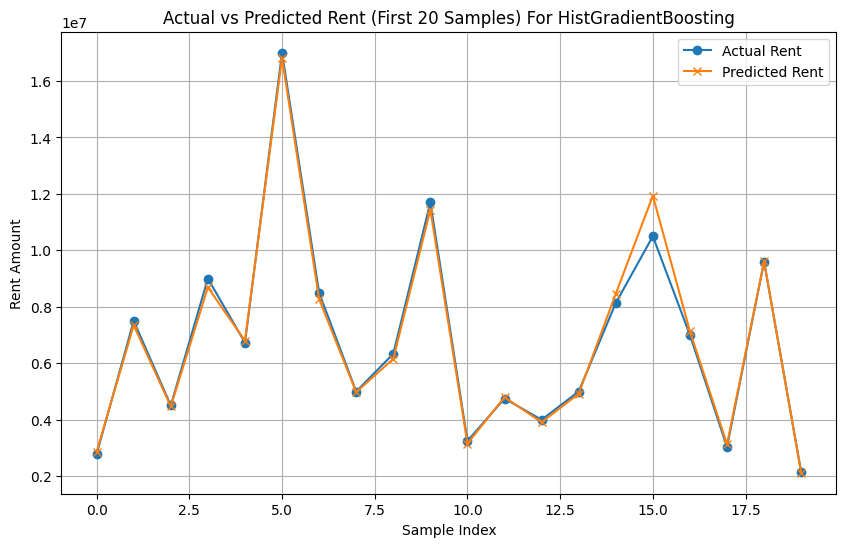

 80%|████████  | 12/15 [00:09<00:01,  1.52it/s]

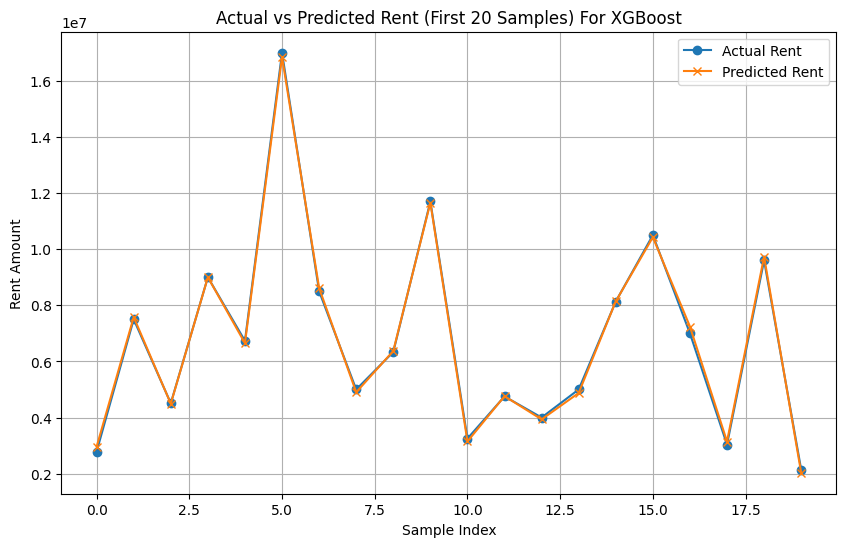

 87%|████████▋ | 13/15 [00:09<00:01,  1.76it/s]

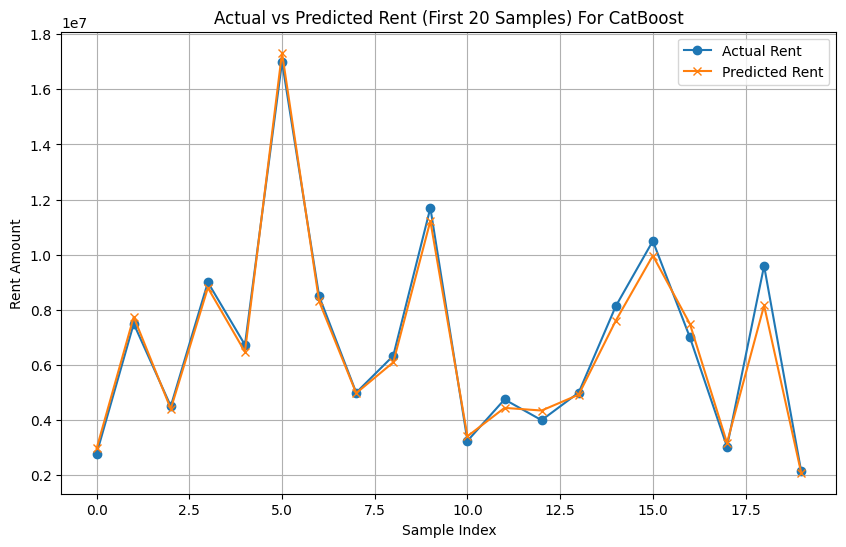

 93%|█████████▎| 14/15 [00:09<00:00,  1.93it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002799 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 570
[LightGBM] [Info] Number of data points in the train set: 3271, number of used features: 10
[LightGBM] [Info] Start training from score 6218563.863956


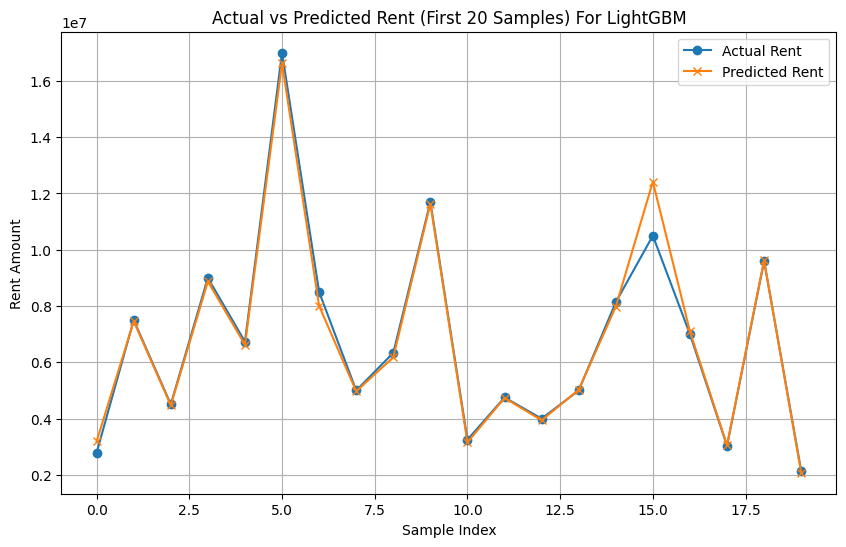

100%|██████████| 15/15 [00:10<00:00,  1.47it/s]


In [32]:
from sklearn.impute import SimpleImputer
import numpy as np

# Impute missing values (NaNs) in the scaled datasets
imputer = SimpleImputer(strategy='median')
x_train_imputed = imputer.fit_transform(x_train)
x_test_imputed = imputer.transform(x_test)

errors={}
for model_name , model in tqdm(models.items()):
    model.fit(x_train_imputed, y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, x_train_imputed, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, x_test_imputed, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    # Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(x_test_imputed[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples) For ' + model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [35]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models using imputed data
model1.fit(x_train_imputed, y_train)
model2.fit(x_train_imputed, y_train)
model3.fit(x_train_imputed, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, x_train_imputed, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, x_test_imputed, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, x_train_imputed, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, x_test_imputed, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, x_train_imputed, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, x_test_imputed, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [39]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

# Fit stacking regressor on imputed data
stacking_regressor.fit(x_train_imputed, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, x_train_imputed, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, x_test_imputed, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [37]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test", ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
ExtraTrees,1.895445e+00,1.216945e+05,2.023846e+03,5.058226e+11,4.498718e+01,7.112121e+05,1.000000,0.981030
Simple Voting,2.468932e+05,2.905488e+05,2.304580e+11,8.612785e+11,4.800604e+05,9.280509e+05,0.988875,0.967699
Voting,2.468932e+05,2.905488e+05,2.304580e+11,8.612785e+11,4.800604e+05,9.280509e+05,0.988875,0.967699
Random Forest,8.626566e+04,1.772380e+05,8.607721e+10,9.164647e+11,2.933892e+05,9.573216e+05,0.995845,0.965630
Weighted Voting,2.918710e+05,3.285280e+05,2.947000e+11,9.167312e+11,5.428628e+05,9.574608e+05,0.985774,0.965620
GradientBoosting,1.873724e+05,2.482079e+05,1.293349e+11,9.868921e+11,3.596316e+05,9.934244e+05,0.993757,0.962988
Bagging,9.119154e+04,1.830910e+05,1.531189e+11,1.190555e+12,3.913041e+05,1.091126e+06,0.992609,0.955350
Decision Tree,1.212754e+05,3.228921e+05,4.363657e+10,1.455538e+12,2.088937e+05,1.206457e+06,0.997894,0.945413
Ridge,7.211921e+05,6.958686e+05,1.678368e+12,1.833185e+12,1.295518e+06,1.353952e+06,0.918982,0.931250
Linear Regression,7.213713e+05,6.961093e+05,1.678365e+12,1.833517e+12,1.295517e+06,1.354074e+06,0.918982,0.931237


<Axes: >

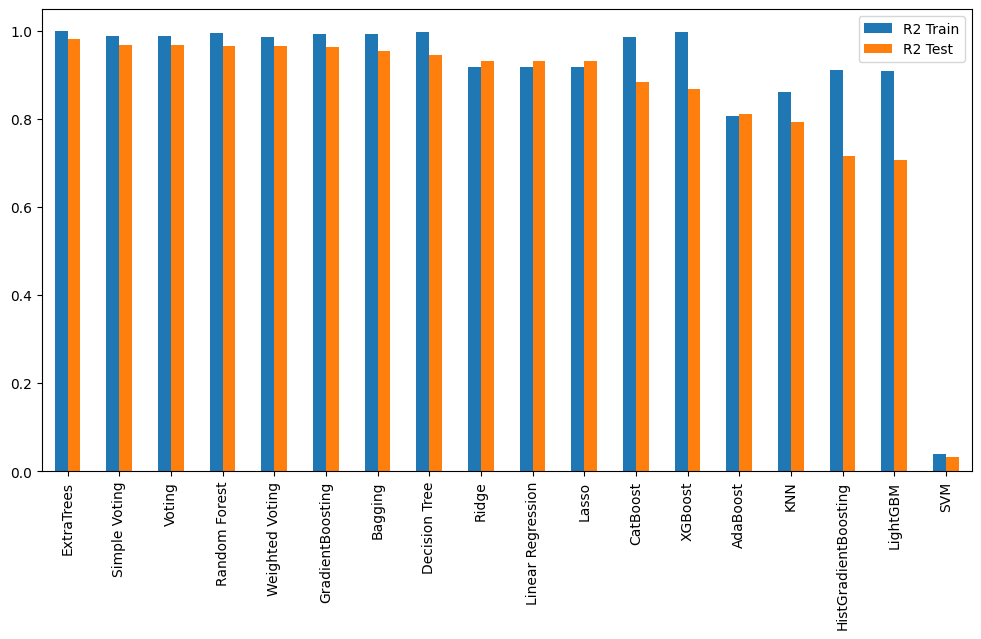

In [40]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

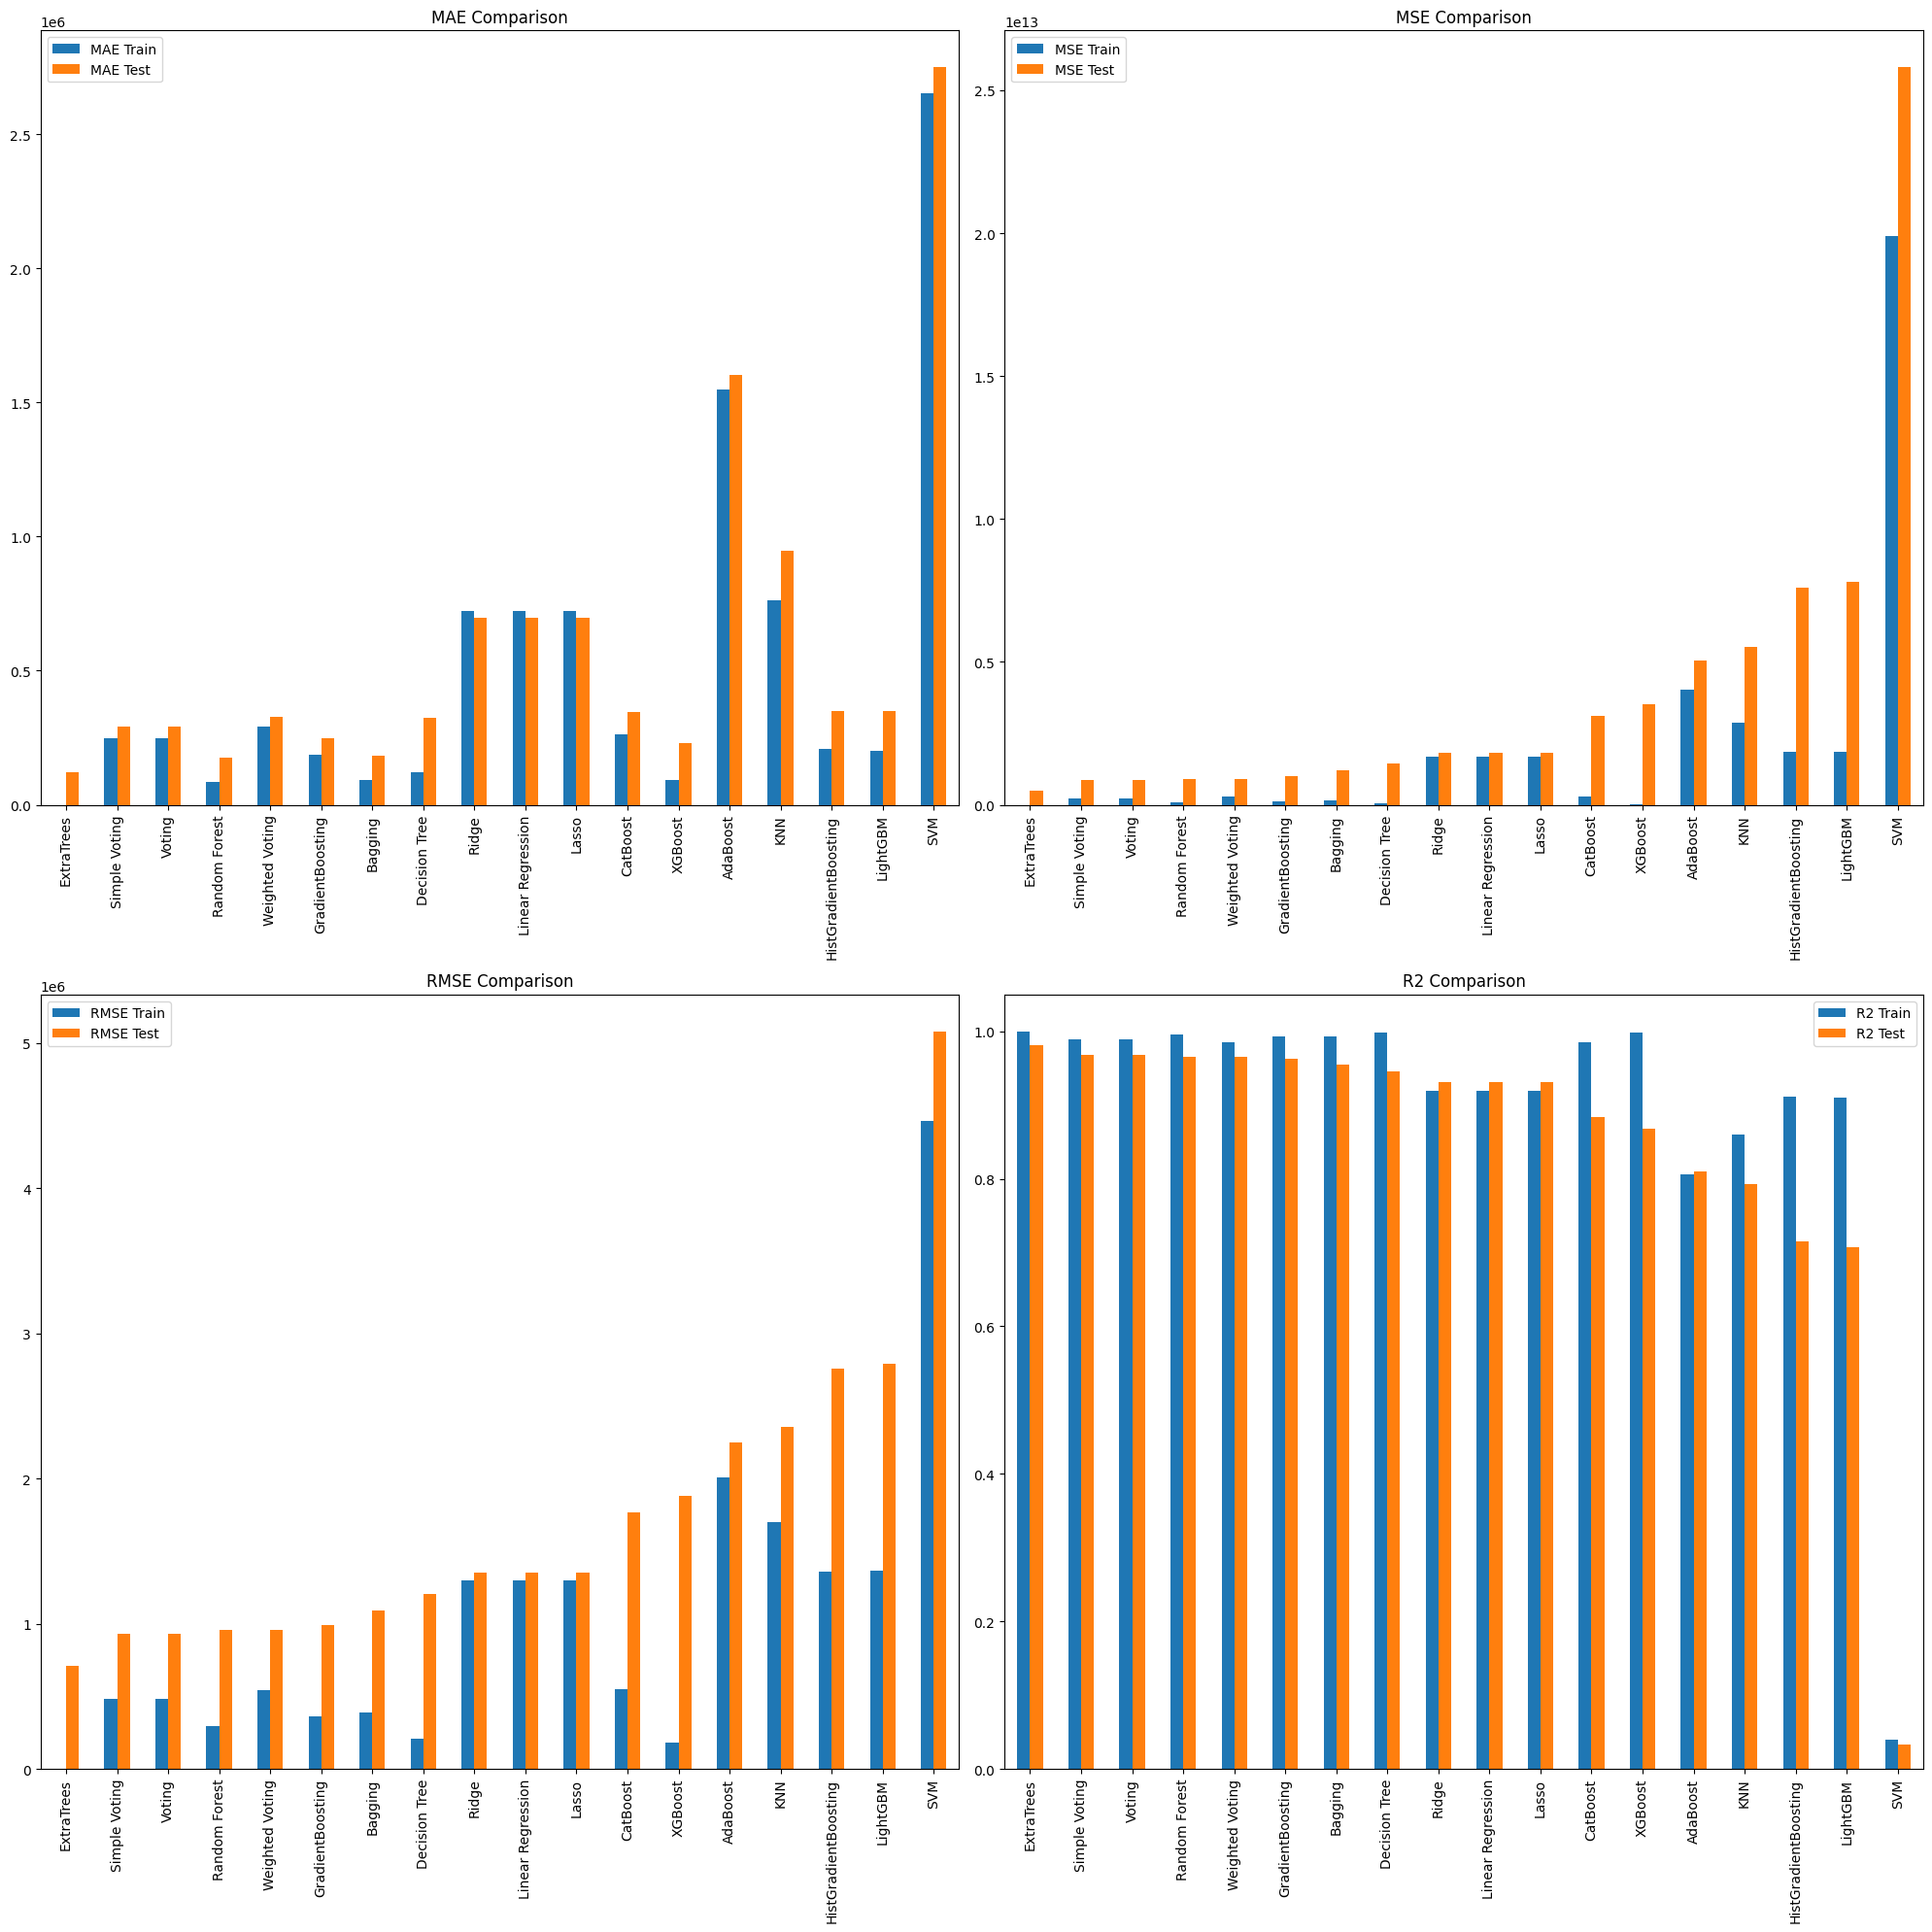

In [41]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [43]:
from sklearn.decomposition import PCA

print(x_train_imputed.shape)

pca = PCA(n_components=3, random_state=42)
x_train_pca = pca.fit_transform(x_train_imputed)
x_test_pca = pca.transform(x_test_imputed)
print(x_test_pca.shape)

(3271, 10)
(818, 3)


<Figure size 1000x600 with 0 Axes>

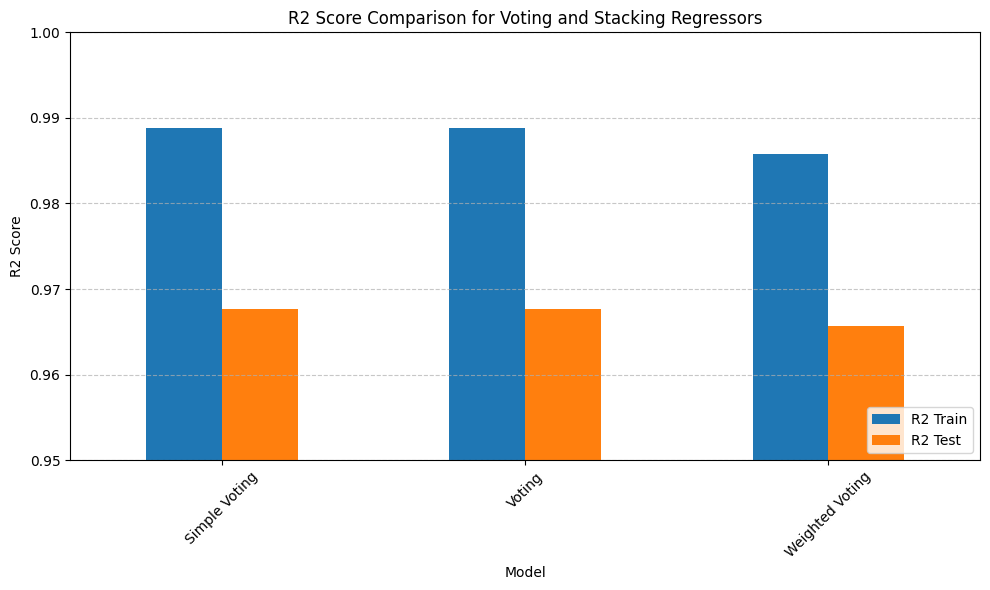

In [44]:

ensemble_models = ["Voting", "Simple Voting", "Weighted Voting", "Stacking"]
filtered_errors = errors_df.loc[errors_df.index.isin(ensemble_models)]

plt.figure(figsize=(10, 6))
filtered_errors[["R2 Train", "R2 Test"]].plot.bar(figsize=(10, 6))
plt.title("R2 Score Comparison for Voting and Stacking Regressors")
plt.ylabel("R2 Score")
plt.xlabel("Model")
plt.ylim(0.95, 1.0)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()